
# Project B | 통계적 시계열 예측 모델링

## B-09. ETS 및 ARIMA 기반 주간 수요 예측

### 1. 분석 목적

앞선 B-08에서는 Naive Forecast와 4주 이동평균(MA4)을 기준 모델로 구축하고, 상품군별·예측 시차별 성능을 비교하였다.

분석 결과, 1주 후 예측에서는 모든 상품군에서 Naive가 우수했으나, 4주 후 예측에서는 5개 상품군 중 4개에서 MA4가 더 우수하였다.

이번 분석에서는 시계열의 수준, 추세 및 자기상관 구조를 반영하는 **ETS와 ARIMA 모델**을 적용하여 기존 기준 모델 대비 예측 성능의 개선 여부를 검증한다.

### 2. 데이터 및 검증 조건

| 항목 | 설정 |
|---|---|
| 데이터 | Olist 주간 상품군별 주문 상품 수량 |
| 분석 대상 | 상위 5개 상품군 |
| 전체 관측 기간 | 76주 |
| 학습·모델 검증 | 최초 64주 |
| 최종 평가 | 마지막 12주 |
| 예측 기간 | 향후 1~4주 |
| 최초 학습 길이 | 32주 |
| 검증 방법 | Expanding-window Rolling-origin |
| 예측 시작점 | 상품군별 29개 |
| 평가 지표 | MAE, WAPE |

최종 12주 데이터는 모델 선정 과정에서 사용하지 않으며, 모든 모델에 동일한 검증 조건을 적용한다.

### 3. 비교 모델

#### 3.1. ETS (Exponential Smoothing)

시계열의 수준(Level), 추세(Trend), 계절성(Seasonality)을 반영하는 지수평활 기반 예측 모형이다.

우선 다음 세 가지 비계절 모형을 비교한다.

- **ETS(A,N,N):** 수준만 반영하는 단순 지수평활 모형
- **ETS(A,A,N):** 가법 선형 추세를 포함하는 모형
- **ETS(A,Ad,N):** 감쇠 가법 추세를 포함하는 모형

상품군당 학습 데이터가 64주로 제한되어 있고 연간 계절성이 명확하게 확인되지 않았으므로, 초기 모델에서는 계절성 성분을 제외한다.

#### 3.2. ARIMA (Autoregressive Integrated Moving Average)

과거 관측값의 자기상관과 오차 구조를 활용하는 시계열 모형이다.

ARIMA(p,d,q)의 각 요소는 다음과 같다.

- **p:** 자기회귀(AR) 차수
- **d:** 차분(I) 차수
- **q:** 이동평균(MA) 차수

B-07에서 수행한 ACF·PACF 분석과 ADF 단위근 검정 결과를 참고하되, 모형 차수는 검증 성능과 잔차 진단을 함께 고려하여 선정한다.

ARIMA의 MA 성분은 과거 예측오차를 모형화하는 것으로, B-08에서 사용한 단순 이동평균 예측(MA4)과는 구분된다.

### 4. 분석 절차

1. 데이터 로딩 및 학습 구간 재현
2. ETS 단일 상품군 적합 및 예측
3. ETS 후보 모형별 Rolling-origin 검증
4. ARIMA 후보 모형 탐색 및 예측
5. 상품군별·Horizon별 성능 비교
6. 잔차 진단 및 모델 선정
7. Naive·MA4 대비 개선 여부 평가

### 5. 분석 시 주의사항

- 예측 기준 시점 이후의 실제 관측값은 모델 적합에 사용하지 않는다.
- 모든 모델에서 동일한 예측 시작점과 Horizon을 사용한다.
- 모델별 적합 실패 및 수렴 경고를 기록한다.
- 예측 성능이 좋더라도 잔차의 자기상관과 예측값의 타당성을 확인한다.
- 계산 비용을 고려하여 후보 모형의 범위를 제한한다.
- 모델 비교 후 선정된 최종 후보에 한해 별도 12주 평가를 수행한다.

### 6. 기대 결과

상품군별 수요 변화 특성에 적합한 통계적 예측 모델을 선정하고, Naive·MA4 기준 모델 대비 개선 여부를 정량적으로 평가한다.

궁극적으로 향후 1~4주 수요 전망을 제공하여 재고 및 프로모션 운영 계획 수립을 지원하는 것을 목표로 한다.


In [1]:
# TASK B-09-1. 분석 환경 설정

# 데이터 처리
import pandas as pd
import numpy as np

# 시각화
import matplotlib.pyplot as plt

# PostgreSQL
import os
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from dotenv import load_dotenv, find_dotenv

# 시계열 모델
import statsmodels
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

# 성능 평가
from sklearn.metrics import mean_absolute_error

print('statsmodels:', statsmodels.__version__)
print('ETSModel import: PASS')

statsmodels: 0.15.0
ETSModel import: PASS


In [2]:
# 1. 환경변수 로드
load_dotenv(find_dotenv(usecwd=True))

# 2. 데이터베이스 접속 정보 구성
db_url = URL.create(
    drivername='postgresql+psycopg',
    username=os.getenv('DB_USER'),
    password=os.getenv('DB_PASSWORD'),
    host=os.getenv('DB_HOST'),
    port=int(os.getenv('DB_PORT', '5432')),
    database=os.getenv('DB_NAME')
)
# 3. SQLAlchemy 엔진 생성
engine = create_engine(db_url, pool_pre_ping=True)

# 4. 연결 후 SQL 실행
with engine.connect() as conn:
    view_count = conn.execute(text('SELECT COUNT(*) FROM analytics.v_weekly_category_demand')).scalar_one()
print('PostgreSQL View 연결 성공 | 행 수:', view_count)

PostgreSQL View 연결 성공 | 행 수: 380


In [3]:
# TASK B-09-2. 주간 수요 데이터 로딩

# analytics.v_weekly_category_demand 전체 조회 SQL 작성
query = '''
    SELECT  * 
      FROM  analytics.v_weekly_category_demand
     ORDER
        BY  product_category_name, week_start; 
'''

# pd.read_sql()로 DataFrame 생성
with engine.connect() as conn:
    df = pd.read_sql(text(query), conn)


# week_start 컬럼을 datetime 타입으로 변환
df['week_start'] = pd.to_datetime(df['week_start'])

# 데이터 확인
print('데이터 크기:', df.shape)
display(df.head())
print(df.dtypes)

데이터 크기: (380, 3)


,product_category_name,week_start,weekly_items
0,beleza_saude,2017-03-06,43
1,beleza_saude,2017-03-13,52
2,beleza_saude,2017-03-20,56
3,beleza_saude,2017-03-27,44
4,beleza_saude,2017-04-03,37


product_category_name              str
week_start               datetime64[s]
weekly_items                     int64
dtype: object


In [4]:
# TASK B-09-3. 학습·평가 데이터 분리

# 상품군, 주차 순으로 오름차순 정렬
df_sorted = df.sort_values(by=['product_category_name', 'week_start'],
    ascending=[True, True]).copy()

# 학습 종료일 지정
train_end = pd.Timestamp('2018-05-21')

# 학습 데이터 추출
training_df = df_sorted[df_sorted['week_start'] <= train_end].copy()

# 최종 평가 데이터 추출
test_df = df_sorted[df_sorted['week_start'] > train_end].copy()

# 분리 결과 확인
print('학습:', len(training_df))
print('평가:', len(test_df))

학습: 320
평가: 60


In [5]:
# TASK B-09-4. ETS 모델링을 위한 데이터 및 평가 함수 준비

# cama_mesa_banho 상품군만 추출
category_df = training_df[
    training_df.product_category_name == 'cama_mesa_banho'
].copy()

# 주차 오름차순 정렬
category_df = category_df.sort_values(by='week_start', ascending=True).copy()

# 최초 60주를 history로 추출
history = category_df.iloc[:-4]

# 마지막 4주를 actual로 추출
actual = category_df.iloc[-4:]

# WAPE 함수 정의
def wape(y_true, y_pred):
    numerator = np.abs(y_true - y_pred).sum()
    denominator = np.abs(y_true).sum()
    if denominator == 0:
        raise ValueError("WAPE를 계산할 수 없습니다: 실제값의 절댓값 합계가 0입니다.")
    
    return numerator / denominator * 100

# naive forecast 함수 정의
def naive_forecast(history, horizon=4):
    last_value = history.iloc[-1]['weekly_items']
    pred = np.repeat(last_value, horizon)
    return pred


In [6]:
# TASK B-09-5. ETS(A,N,N) 단일 상품군 적합

# history에서 주문 수량만 추출
y_train = history['weekly_items'].reset_index(drop=True)

# ETS(A,N,N) 모델 정의
model = ETSModel(
    y_train,
    error='add',
    trend=None,
    seasonal=None
)

# 모델 적합
fitted_model = model.fit(disp=False)

# 향후 4주 예측
pred_ets = fitted_model.forecast(steps=4)

# 실제값과 예측값 확인
print(type(y_train.index))
print('학습 길이:', len(y_train))
print('예측 길이:', len(pred_ets))
print('예측값:', pred_ets.to_numpy())
print('실제값:', actual['weekly_items'].to_numpy())

<class 'pandas.RangeIndex'>
학습 길이: 60
예측 길이: 4
예측값: [175.2285176 175.2285176 175.2285176 175.2285176]
실제값: [187 164 218 133]


In [7]:
# TASK B-09-6. ETS 평활계수 및 예측 성능 평가

# 추정된 모델 파라미터 확인
print(fitted_model.params)

# 실제값과 ETS 예측값을 NumPy 배열로 변환
y_true = actual['weekly_items'].to_numpy()
y_pred = pred_ets.to_numpy()

# ETS의 MAE 계산
mae_ets = mean_absolute_error(y_true, y_pred)

# ETS의 WAPE 계산
wape_ets = wape(y_true, y_pred)

# 같은 시점의 Naive Forecast 생성
pred_naive = naive_forecast(history, 4)

# Naive의 MAE·WAPE 계산
mae_naive = mean_absolute_error(y_true, pred_naive)
wape_naive = wape(y_true, pred_naive)

# 결과 출력
comparison_df = pd.DataFrame({
    'model': ['Naive', 'ETS(A,N,N)'],
    'MAE': [mae_naive, mae_ets],
    'WAPE': [wape_naive, wape_ets]
})

display(comparison_df.round(2))

0     0.206324
1    64.933871
dtype: float64


,model,MAE,WAPE
0,Naive,28.5,16.24
1,"ETS(A,N,N)",27.0,15.38


In [8]:
print(list(zip(fitted_model.model.param_names, fitted_model.params)))

[('smoothing_level', 0.20632350637399463), ('initial_level', 64.93387077039782)]


In [9]:
# TASK B-09-7. ETS(A,A,N) 추세 모델 적합

# ETS(A,A,N) 정의
model_trend = ETSModel(
    y_train,
    error='additive',
    trend='additive',
    seasonal=None
)

# 모델 적합
fitted_trend = model_trend.fit(disp=False)

# 향후 4주 예측
pred_trend = fitted_trend.forecast(steps=4)

# 파라미터와 예측값 확인
print(fitted_trend.model.param_names)
print(fitted_trend.params)
print(pred_trend)

['smoothing_level', 'smoothing_trend', 'initial_level', 'initial_trend']
0    1.000000e-04
1    1.000000e-08
2    6.359987e+01
3    2.297797e+00
dtype: float64
60    203.765494
61    206.063291
62    208.361088
63    210.658885
Name: simulation, dtype: float64


In [10]:
# TASK B-09-8. ETS(A,Ad,N) 감쇠 추세 모델 적합

# 감쇠 추세 ETS 모델 정의
model_damped = ETSModel(
    y_train,
    error='additive',
    trend='additive',
    damped_trend=True,
    seasonal=None
)

# 모델 적합
fitted_damped = model_damped.fit(disp=False)

# 향후 4주 예측
pred_damped = fitted_damped.forecast(steps=4)

# 수렴 여부, 파라미터 및 예측값 출력
print(list(zip(
    fitted_damped.model.param_names,
    fitted_damped.params
)))

print('4주 예측값:', pred_damped.to_numpy())

[('smoothing_level', 0.0001), ('smoothing_trend', 9.998670445588775e-05), ('damping_trend', 0.9782529060954788), ('initial_level', 45.14409802552802), ('initial_trend', 4.368043908523597)]
4주 예측값: [190.2715315  191.3884206  192.4810206  193.54985972]


In [11]:
# TASK B-09-9. ETS 후보 모형 단일 예측 성능 비교

models_pred = {
    'Naive': pred_naive,
    'ETS(A,N,N)': pred_ets,
    'ETS(A,A,N)': pred_trend,
    'ETS(A,Ad,N)': pred_damped
}

model_metrics = []

for model_name, y_pred in models_pred.items():

    # y_pred를 NumPy 배열로 변환
    y_pred = np.asarray(y_pred)
    # MAE와 WAPE 계산
    mae = mean_absolute_error(y_true, y_pred)
    wape_value = wape(y_true,y_pred)
    # model_name, MAE, WAPE를 딕셔너리로 저장
    model_metrics.append({
        'model': model_name,
        'MAE': mae,
        'WAPE': wape_value
    })

# DataFrame 생성 및 WAPE 오름차순 정렬
model_metrics_df = pd.DataFrame(model_metrics)
model_metrics_df = model_metrics_df.sort_values('WAPE')

display(model_metrics_df.round(2))

,model,MAE,WAPE
1,"ETS(A,N,N)",27.00,15.38
0,Naive,28.50,16.24
3,"ETS(A,Ad,N)",29.18,16.63
2,"ETS(A,A,N)",36.53,20.82


In [12]:
# TASK B-09-10. ETS 예측 함수 설계

def ets_forecast(history, horizon=4, model_type='ANN', return_convergence=False):
    # 주문 수량 Series 추출 및 인덱스 초기화
    y_train = history['weekly_items'].reset_index(drop=True)
    # model_type에 따라 ETS 설정 구분
    model_dic = {
        'ANN' : [None, False],
        'AAN' : ['add', False],
        'AdN' : ['add', True],        
    }
    # ETSModel 생성
    model = ETSModel(
        y_train,
        trend=model_dic[model_type][0],
        damped_trend=model_dic[model_type][1]
    )
    # 모델 적합 및 예측
    fitted = model.fit(disp=False)
    pred = fitted.forecast(steps=horizon)

    # 수렴여부 확인 및 horizon주 예측값 반환
    converged = fitted.mle_retvals.get('converged', False)

    if return_convergence:
        return np.asarray(pred), converged
    
    return np.asarray(pred)


In [13]:
# TASK B-09-11. ETS 예측 함수 검증

pred_ann = ets_forecast(history, horizon=4, model_type='ANN')
pred_aan = ets_forecast(history, horizon=4, model_type='AAN')
pred_adn = ets_forecast(history, horizon=4, model_type='AdN')

# 모델별 예측값 비교
result_df = pd.DataFrame({
    'horizon': range(1, 5),
    'ETS_ANN': pred_ann,
    'ETS_AAN': pred_aan,
    'ETS_AdN': pred_adn
})

display(result_df.round(2))

,horizon,ETS_ANN,ETS_AAN,ETS_AdN
0,1,175.23,203.77,190.27
1,2,175.23,206.06,191.39
2,3,175.23,208.36,192.48
3,4,175.23,210.66,193.55


In [14]:
# TASK B-09-12. ETS Rolling-origin 검증

min_history = 32
horizon = 4
model_types = ['ANN', 'AAN', 'AdN']

ets_results = []
ets_failures = []

# 상품군별 반복
for category, group in training_df.groupby('product_category_name'):

    # 날짜순 정렬
    category_df = category_df = group.sort_values('week_start').copy()

    # 예측 시작점별 반복
    for start_point in range(min_history, len(group['week_start'])- horizon + 1):

        # 학습·검증 구간 추출
        training = category_df.iloc[:start_point]
        actual = category_df.iloc[start_point:start_point + horizon]
    
        # ETS 모델 3종 반복
        for model_type in model_types:
    
            # 예측 및 오류 처리
            try:
                pred, converged = ets_forecast(
                    training,
                    horizon=horizon,
                    model_type=model_type,
                    return_convergence=True
                )

                # 예측값이 유한한 숫자인지 확인
                assert np.isfinite(pred).all()

                # Horizon별 예측 결과 저장
                for h in range(1, horizon + 1):
                    ets_results.append({
                        'category': category,
                        'model': model_type,
                        'origin_date': training.iloc[-1]['week_start'],
                        'target_date': actual.iloc[h-1]['week_start'],
                        'horizon': h,
                        'y_true': actual.iloc[h-1]['weekly_items'],
                        'y_pred': pred[h-1],
                        'converged': converged
                    })

            except Exception as e:
                # 오류 정보 저장
                ets_failures.append({
                    'category': category,
                    'model': model_type,
                    'start_point': start_point,
                    'error': str(e)
                })

ets_results_df = pd.DataFrame(ets_results)
ets_failures_df = pd.DataFrame(ets_failures)

print('예측 결과:', ets_results_df.shape)
print('적합 실패 횟수:', len(ets_failures_df))

if not ets_results_df.empty:
    print('수렴 여부:')
    print(ets_results_df.groupby(['model', 'converged']).size())

if not ets_failures_df.empty:
    display(ets_failures_df.head())

ets_results_df

예측 결과: (1740, 8)
적합 실패 횟수: 0
수렴 여부:
model  converged
AAN    True         580
ANN    True         580
AdN    True         580
dtype: int64


,category,model,origin_date,target_date,horizon,y_true,y_pred,converged
0,beleza_saude,ANN,2017-10-09,2017-10-16,1,108,75.143810,True
1,beleza_saude,ANN,2017-10-09,2017-10-23,2,86,75.143810,True
2,beleza_saude,ANN,2017-10-09,2017-10-30,3,64,75.143810,True
3,beleza_saude,ANN,2017-10-09,2017-11-06,4,87,75.143810,True
4,beleza_saude,AAN,2017-10-09,2017-10-16,1,108,89.524244,True
...,...,...,...,...,...,...,...,...
1735,moveis_decoracao,AAN,2018-04-23,2018-05-21,4,84,153.561150,True
1736,moveis_decoracao,AdN,2018-04-23,2018-04-30,1,141,135.544685,True
1737,moveis_decoracao,AdN,2018-04-23,2018-05-07,2,176,135.545159,True
1738,moveis_decoracao,AdN,2018-04-23,2018-05-14,3,176,135.545538,True


In [15]:
# TASK B-09-14. ETS 모델별 Rolling-origin 성능 평가

ets_metrics = []

# category, model, horizon별 그룹화
for (category, model, h), group in ets_results_df.groupby(['category', 'model', 'horizon']):

    # MAE 계산
    mae_value = mean_absolute_error(group['y_true'],group['y_pred'])

    # WAPE 계산
    wape_value = wape(group['y_true'],group['y_pred'])

    # 결과 저장
    ets_metrics.append({
        'category': category,
        'model': model,
        'horizon': h,
        'n_predictions': len(group),
        'MAE': mae_value,
        'WAPE': wape_value
    })

# DataFrame 생성
ets_metrics_df = pd.DataFrame(ets_metrics)

display(ets_metrics_df.round(2))

assert ets_metrics_df.shape == (60, 6)
assert ets_metrics_df['n_predictions'].eq(29).all()

print('ETS 성능 평가 검증: PASS')

,category,model,horizon,n_predictions,MAE,WAPE
0,beleza_saude,AAN,1,29,29.67,20.86
1,beleza_saude,AAN,2,29,33.41,22.73
2,beleza_saude,AAN,3,29,34.24,22.85
3,beleza_saude,AAN,4,29,35.79,23.70
4,beleza_saude,ANN,1,29,29.07,20.44
5,beleza_saude,ANN,2,29,38.74,26.36
6,beleza_saude,ANN,3,29,44.48,29.68
7,beleza_saude,ANN,4,29,48.51,32.12
8,beleza_saude,AdN,1,29,32.85,23.10
9,beleza_saude,AdN,2,29,38.44,26.15


ETS 성능 평가 검증: PASS


In [16]:
# TASK B-09-15. ETS 모델별 WAPE 교차표

# 행은 category와 horizon
index = ['category', 'horizon']
# 열은 model
columns= 'model'
# 값은 WAPE
value = 'WAPE'
ets_wape_pivot = ets_metrics_df.pivot_table(
    index=index,
    columns=columns,
    values=value
    )

display(ets_wape_pivot.round(2))

model                             AAN    ANN    AdN
category               horizon                     
beleza_saude           1        20.86  20.44  23.10
                       2        22.73  26.36  26.15
                       3        22.85  29.68  28.45
                       4        23.70  32.12  28.61
cama_mesa_banho        1        23.63  20.83  20.57
                       2        26.27  24.64  23.72
                       3        26.44  24.91  24.39
                       4        28.53  25.03  26.11
esporte_lazer          1        21.02  17.37  21.21
                       2        22.41  22.65  22.84
                       3        23.03  25.45  23.76
                       4        25.77  28.81  26.65
informatica_acessorios 1        27.35  26.74  29.55
                       2        36.40  35.42  36.67
                       3        42.02  40.88  40.57
                       4        48.73  46.49  45.92
moveis_decoracao       1        38.87  35.57  42.59
                       2        47.88  42.90  50.32
                       3        52.06  41.98  53.83
                       4        56.23  40.73  57.04

In [17]:
# TASK B-09-16. Naive·MA4 Rolling-origin 예측 결과 생성

baseline_results = []

min_history = 32
horizon = 4

for category, group in training_df.groupby('product_category_name'):

    category_df = group.sort_values('week_start').reset_index(drop=True)

    for start_point in range(min_history, len(category_df) - horizon + 1):

        history = category_df.iloc[:start_point]
        actual = category_df.iloc[start_point:start_point + horizon]

        # Naive: 마지막 관측값
        pred_naive = history['weekly_items'].iloc[-1]

        # MA4: 최근 4주 평균
        pred_ma4 = history['weekly_items'].iloc[-4:].mean()

        for model_name, pred_value in [
            ('Naive', pred_naive),
            ('MA4', pred_ma4)
        ]:
            for h in range(1, horizon + 1):

                baseline_results.append({
                    'category': category,
                    'model': model_name,
                    'origin_date': history['week_start'].iloc[-1],
                    'target_date': actual['week_start'].iloc[h - 1],
                    'horizon': h,
                    'y_true': actual['weekly_items'].iloc[h - 1],
                    'y_pred': pred_value
                })

baseline_results_df = pd.DataFrame(baseline_results)

# 결과 검증
assert baseline_results_df.shape == (1160, 7)
assert baseline_results_df.groupby('model').size().eq(580).all()

print('Baseline 예측 결과:', baseline_results_df.shape)
display(baseline_results_df.head())

Baseline 예측 결과: (1160, 7)


,category,model,origin_date,target_date,horizon,y_true,y_pred
0,beleza_saude,Naive,2017-10-09,2017-10-16,1,108,69.0
1,beleza_saude,Naive,2017-10-09,2017-10-23,2,86,69.0
2,beleza_saude,Naive,2017-10-09,2017-10-30,3,64,69.0
3,beleza_saude,Naive,2017-10-09,2017-11-06,4,87,69.0
4,beleza_saude,MA4,2017-10-09,2017-10-16,1,108,77.0


In [18]:
# TASK B-09-17. 전체 모델 예측 결과 통합

all_forecasts_df = pd.concat(
    [
        baseline_results_df,
        ets_results_df
    ],
    ignore_index=True
)

print('전체 결과:', all_forecasts_df.shape)
print(all_forecasts_df.groupby('model').size())

assert all_forecasts_df.shape[0] == 2900

전체 결과: (2900, 8)
model
AAN      580
ANN      580
AdN      580
MA4      580
Naive    580
dtype: int64


In [19]:
# TASK B-09-18. 전체 모델 Rolling-origin 성능 비교
all_metrics = []

for (category, model, h), group in all_forecasts_df.groupby(
    ['category', 'model', 'horizon']
):
    y_true = group['y_true'].to_numpy()
    y_pred = group['y_pred'].to_numpy()

    mae_value = mean_absolute_error(y_true, y_pred)

    denominator = np.abs(y_true).sum()
    wape_value = (
        np.abs(y_true - y_pred).sum() / denominator * 100
        if denominator > 0 else np.nan
    )

    all_metrics.append({
        'category': category,
        'model': model,
        'horizon': h,
        'n_predictions': len(group),
        'MAE': mae_value,
        'WAPE': wape_value
    })

all_metrics_df = pd.DataFrame(all_metrics)

# 결과 검증
assert all_metrics_df.shape == (100, 6)
assert all_metrics_df['n_predictions'].eq(29).all()

# 모델별 WAPE 교차표
wape_pivot = all_metrics_df.pivot_table(
    index=['category', 'horizon'],
    columns='model',
    values='WAPE'
)

display(wape_pivot.round(2))

model                             AAN    ANN    AdN    MA4  Naive
category               horizon                                   
beleza_saude           1        20.86  20.44  23.10  24.04  19.64
                       2        22.73  26.36  26.15  28.39  28.41
                       3        22.85  29.68  28.45  28.76  32.05
                       4        23.70  32.12  28.61  29.76  35.68
cama_mesa_banho        1        23.63  20.83  20.57  24.12  21.99
                       2        26.27  24.64  23.72  27.90  27.19
                       3        26.44  24.91  24.39  28.27  29.51
                       4        28.53  25.03  26.11  28.29  31.81
esporte_lazer          1        21.02  17.37  21.21  20.22  17.43
                       2        22.41  22.65  22.84  25.07  24.34
                       3        23.03  25.45  23.76  25.97  27.40
                       4        25.77  28.81  26.65  28.69  31.89
informatica_acessorios 1        27.35  26.74  29.55  33.11  25.80
                       2        36.40  35.42  36.67  40.50  34.45
                       3        42.02  40.88  40.57  44.55  40.05
                       4        48.73  46.49  45.92  48.15  45.31
moveis_decoracao       1        38.87  35.57  42.59  35.62  29.75
                       2        47.88  42.90  50.32  37.60  40.38
                       3        52.06  41.98  53.83  35.48  44.59
                       4        56.23  40.73  57.04  33.39  44.46

In [20]:
# Horizon 4 성능 비교

h4_wape = wape_pivot.xs(4, level='horizon')

h4_summary = pd.DataFrame({
    'best_model': h4_wape.idxmin(axis=1),
    'best_WAPE': h4_wape.min(axis=1),
    'Naive_WAPE': h4_wape['Naive']
})

h4_summary['improvement_pct'] = (
    (h4_summary['Naive_WAPE'] - h4_summary['best_WAPE'])
    / h4_summary['Naive_WAPE'] * 100
)

display(h4_summary.round(2))

,best_model,best_WAPE,Naive_WAPE,improvement_pct
category,,,,
beleza_saude,AAN,23.70,35.68,33.59
cama_mesa_banho,ANN,25.03,31.81,21.30
esporte_lazer,AAN,25.77,31.89,19.19
informatica_acessorios,Naive,45.31,45.31,0.00
moveis_decoracao,MA4,33.39,44.46,24.90


In [21]:
# TASK B-09-19. ARIMA 첫 번째 모델

from statsmodels.tsa.arima.model import ARIMA

# cama_mesa_banho의 최초 60주
arima_category = (
    training_df[
        training_df['product_category_name'] == 'cama_mesa_banho'
    ]
    .sort_values('week_start')
    .reset_index(drop=True)
)

y_train = arima_category['weekly_items'].iloc[:60]

model = ARIMA(
    y_train,
    order=(0, 1, 0),
    trend='n'
)

fitted = model.fit()
pred_arima = fitted.forecast(steps=4)

print('ARIMA 예측:', np.asarray(pred_arima))
print('Naive 예측:', np.repeat(y_train.iloc[-1], 4))

print(
    'Naive와 일치:',
    np.allclose(pred_arima, y_train.iloc[-1])
)

ARIMA 예측: [161. 161. 161. 161.]
Naive 예측: [161 161 161 161]
Naive와 일치: True


In [22]:
# TASK B-09-20. ARIMA 후보 모델 비교

orders = [(0,1,0), (1,1,0), (0,1,1), (1,1,1)]

y_true = arima_category['weekly_items'].iloc[60:64].to_numpy()

arima_results = []

for order in orders:

    # ARIMA 모델 생성
    model = ARIMA(
        y_train,
        order= order,
        trend='n'
    )

    # 모델 적합
    fitted = model.fit()

    # 향후 4주 예측
    pred = fitted.forecast(steps=4)

    # MAE, WAPE 계산
    mae_value = mean_absolute_error(y_true, pred)
    wape_value = wape(y_true, pred)

    arima_results.append({
        'order': str(order),
        'MAE': mae_value,
        'WAPE': wape_value
    })

arima_comparison_df = pd.DataFrame(arima_results)
display(arima_comparison_df.sort_values('WAPE').round(2))

,order,MAE,WAPE
1,"(1, 1, 0)",26.61,15.16
2,"(0, 1, 1)",27.00,15.38
3,"(1, 1, 1)",27.76,15.82
0,"(0, 1, 0)",28.50,16.24


In [23]:
# TASK B-09-21. ARIMA d=0 후보 비교

orders_d0 = [
    (0, 0, 0),
    (1, 0, 0),
    (0, 0, 1),
    (1, 0, 1)
]

arima_d0_results = []

for order in orders_d0:

    model = ARIMA(
        y_train,
        order=order,
        trend='c'
    )

    fitted = model.fit()
    pred = np.asarray(fitted.forecast(steps=4))

    arima_d0_results.append({
        'order': str(order),
        'MAE': mean_absolute_error(y_true, pred),
        'WAPE': wape(y_true, pred)
    })

arima_d0_df = pd.DataFrame(arima_d0_results)

display(arima_d0_df.sort_values('WAPE').round(2))

,order,MAE,WAPE
3,"(1, 0, 1)",32.75,18.66
1,"(1, 0, 0)",35.48,20.22
2,"(0, 0, 1)",40.77,23.23
0,"(0, 0, 0)",42.16,24.02


In [24]:
# TASK B-09-22. ARIMA 예측 함수

def arima_forecast(history, order, horizon=4, return_convergence=False):

    # 1. 학습 데이터
    y_train = history['weekly_items'].reset_index(drop=True)

    # 2. 차분 차수에 따른 추세항
    d = order[1]
    trend = 'c' if d == 0 else 'n'

    # 3. ARIMA 모델 생성
    model = ARIMA(
        y_train,
        order=order,
        trend=trend
    )

    # 4. 모델 적합 및 예측
    fitted = model.fit()
    pred = np.asarray(fitted.forecast(steps=horizon))

    # 5. 수렴 여부
    converged = fitted.mle_retvals.get('converged', False)

    if return_convergence:
        return pred, converged

    return pred

In [25]:
# 함수 재현성 검증

arima_orders = [
    (0,0,0), (1,0,0), (0,0,1), (1,0,1),
    (0,1,0), (1,1,0), (0,1,1), (1,1,1)
]

check_results = []

for order in arima_orders:

    pred, converged = arima_forecast(
        arima_category.iloc[:60],
        order=order,
        horizon=4,
        return_convergence=True
    )

    check_results.append({
        'order': str(order),
        'WAPE': wape(y_true, pred),
        'converged': converged
    })

check_df = pd.DataFrame(check_results)

display(check_df.sort_values('WAPE').round(2))

,order,WAPE,converged
5,"(1, 1, 0)",15.16,True
6,"(0, 1, 1)",15.38,True
7,"(1, 1, 1)",15.82,True
4,"(0, 1, 0)",16.24,True
3,"(1, 0, 1)",18.66,True
1,"(1, 0, 0)",20.22,True
2,"(0, 0, 1)",23.23,True
0,"(0, 0, 0)",24.02,True


In [26]:
# TASK B-09-23. ARIMA Rolling-origin 검증

import warnings

min_history = 32
horizon = 4

arima_orders = [
    (0,0,0), (1,0,0), (0,0,1), (1,0,1),
    (0,1,0), (1,1,0), (0,1,1), (1,1,1)
]

arima_results = []
arima_fit_logs = []
arima_failures = []

for category, group in training_df.groupby('product_category_name'):

    category_df = (
        group.sort_values('week_start')
             .reset_index(drop=True)
    )

    for start_point in range(
        min_history,
        len(category_df) - horizon + 1
    ):

        history = category_df.iloc[:start_point]
        actual = category_df.iloc[start_point:start_point + horizon]

        origin_date = history['week_start'].iloc[-1]

        for order in arima_orders:

            model_name = f'ARIMA{order}'

            try:
                # 모델 적합 중 발생하는 경고 기록
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter('always')

                    pred, converged = arima_forecast(
                        history,
                        order=order,
                        horizon=horizon,
                        return_convergence=True
                    )

                # 예측값 검증
                if len(pred) != horizon or not np.isfinite(pred).all():
                    raise ValueError("Invalid forecast values")

                # 적합 단위 기록
                arima_fit_logs.append({
                    'category': category,
                    'model': model_name,
                    'origin_date': origin_date,
                    'converged': converged,
                    'warning_count': len(caught)
                })

                # Horizon별 예측 결과 저장
                for h in range(1, horizon + 1):

                    arima_results.append({
                        'category': category,
                        'model': model_name,
                        'origin_date': origin_date,
                        'target_date': actual['week_start'].iloc[h - 1],
                        'horizon': h,
                        'y_true': actual['weekly_items'].iloc[h - 1],
                        'y_pred': pred[h - 1],
                        'converged': converged
                    })

            except Exception as e:

                arima_failures.append({
                    'category': category,
                    'model': model_name,
                    'start_point': start_point,
                    'error': str(e)
                })


arima_results_df = pd.DataFrame(arima_results)
arima_fit_logs_df = pd.DataFrame(arima_fit_logs)
arima_failures_df = pd.DataFrame(arima_failures)

print("예측 결과:", arima_results_df.shape)
print("적합 성공:", len(arima_fit_logs_df))
print("적합 실패:", len(arima_failures_df))

print("\n모델별 수렴 현황")
display(
    arima_fit_logs_df.groupby(['model', 'converged'])
                     .size()
                     .unstack(fill_value=0)
)

print("\n경고 발생 현황")
display(
    arima_fit_logs_df.groupby('model')['warning_count']
                     .agg(['sum', 'max'])
)

if not arima_failures_df.empty:
    display(arima_failures_df.head())

예측 결과: (4640, 8)
적합 성공: 1160
적합 실패: 0

모델별 수렴 현황


converged,True
model,
"ARIMA(0, 0, 0)",145
"ARIMA(0, 0, 1)",145
"ARIMA(0, 1, 0)",145
"ARIMA(0, 1, 1)",145
"ARIMA(1, 0, 0)",145
"ARIMA(1, 0, 1)",145
"ARIMA(1, 1, 0)",145
"ARIMA(1, 1, 1)",145



경고 발생 현황


,sum,max
model,,
"ARIMA(0, 0, 0)",0,0
"ARIMA(0, 0, 1)",1,1
"ARIMA(0, 1, 0)",0,0
"ARIMA(0, 1, 1)",0,0
"ARIMA(1, 0, 0)",1,1
"ARIMA(1, 0, 1)",6,1
"ARIMA(1, 1, 0)",0,0
"ARIMA(1, 1, 1)",79,2


In [27]:
# TASK B-09-24. ARIMA Rolling-origin 성능 평가

arima_metrics = []

for (category, model, h), group in arima_results_df.groupby(
    ['category', 'model', 'horizon']
):
    y_true = group['y_true'].to_numpy()
    y_pred = group['y_pred'].to_numpy()

    arima_metrics.append({
        'category': category,
        'model': model,
        'horizon': h,
        'n_predictions': len(group),
        'MAE': mean_absolute_error(y_true, y_pred),
        'WAPE': wape(y_true, y_pred)
    })

arima_metrics_df = pd.DataFrame(arima_metrics)

# 검증
assert arima_metrics_df.shape == (160, 6)
assert arima_metrics_df['n_predictions'].eq(29).all()

# Horizon 4 성능 비교
arima_h4 = arima_metrics_df[
    arima_metrics_df['horizon'] == 4
]

arima_h4_pivot = arima_h4.pivot_table(
    index='category',
    columns='model',
    values='WAPE'
)

display(arima_h4_pivot.round(2))

model,"ARIMA(0, 0, 0)","ARIMA(0, 0, 1)","ARIMA(0, 1, 0)","ARIMA(0, 1, 1)","ARIMA(1, 0, 0)","ARIMA(1, 0, 1)","ARIMA(1, 1, 0)","ARIMA(1, 1, 1)"
category,,,,,,,,
beleza_saude,45.68,45.63,35.68,32.94,39.65,39.98,34.54,32.69
cama_mesa_banho,34.49,34.53,31.81,25.72,35.12,35.70,31.41,25.45
esporte_lazer,39.03,39.00,31.89,29.03,33.50,32.48,31.01,29.48
informatica_acessorios,49.17,48.91,45.31,46.34,43.83,45.50,45.91,48.66
moveis_decoracao,40.22,40.27,44.46,41.48,43.96,45.68,46.30,44.73


In [28]:
# TASK B-09-25. 전체 13개 모델 비교

# 1. 예측 결과 통합
final_forecasts_df = pd.concat(
    [all_forecasts_df, arima_results_df],
    ignore_index=True
)

# 2. 데이터 무결성 검증
assert final_forecasts_df.shape == (7540, 8)

assert final_forecasts_df.groupby(
    ['category', 'model', 'origin_date', 'horizon']
).size().eq(1).all()

# 3. 모델별 성능 평가
final_metrics = []

for (category, model, h), group in final_forecasts_df.groupby(
    ['category', 'model', 'horizon']
):
    y_true = group['y_true'].to_numpy()
    y_pred = group['y_pred'].to_numpy()

    final_metrics.append({
        'category': category,
        'model': model,
        'horizon': h,
        'n_predictions': len(group),
        'MAE': mean_absolute_error(y_true, y_pred),
        'WAPE': wape(y_true, y_pred)
    })

final_metrics_df = pd.DataFrame(final_metrics)

assert final_metrics_df.shape == (260, 6)
assert final_metrics_df['n_predictions'].eq(29).all()

# 4. Horizon 4 기준 상품군별 최우수 모델
h4_best = (
    final_metrics_df[final_metrics_df['horizon'] == 4]
    .sort_values(['category', 'WAPE'])
    .groupby('category')
    .head(1)
    .reset_index(drop=True)
)

display(h4_best.round(2))

,category,model,horizon,n_predictions,MAE,WAPE
0,beleza_saude,AAN,4,29,35.79,23.70
1,cama_mesa_banho,ANN,4,29,44.81,25.03
2,esporte_lazer,AAN,4,29,36.87,25.77
3,informatica_acessorios,"ARIMA(1, 0, 0)",4,29,63.47,43.83
4,moveis_decoracao,MA4,4,29,45.19,33.39


In [29]:
# TASK B-09-26. Horizon별 최우수 모델

best_by_horizon = (
    final_metrics_df
    .sort_values(['category', 'horizon', 'WAPE'])
    .drop_duplicates(subset=['category', 'horizon'])
    .sort_values(['category', 'horizon'])
)

best_model_pivot = best_by_horizon.pivot(
    index='category',
    columns='horizon',
    values='model'
)

display(best_model_pivot)

horizon,1,2,3,4
category,,,,
beleza_saude,"ARIMA(1, 0, 0)",AAN,AAN,AAN
cama_mesa_banho,"ARIMA(1, 1, 1)",AdN,AdN,ANN
esporte_lazer,"ARIMA(1, 0, 0)","ARIMA(1, 1, 1)",AAN,AAN
informatica_acessorios,"ARIMA(1, 0, 0)","ARIMA(0, 1, 0)","ARIMA(0, 1, 0)","ARIMA(1, 0, 0)"
moveis_decoracao,"ARIMA(0, 1, 0)",MA4,MA4,MA4


In [30]:
# TASK B-09-27. 전체 Horizon 통합 WAPE 계산

temp_df = final_forecasts_df.copy()

temp_df['abs_error'] = (
    temp_df['y_true'] - temp_df['y_pred']
).abs()

temp_df['abs_true'] = temp_df['y_true'].abs()

pooled_metrics_df = (
    temp_df.groupby(['category', 'model'])
    .agg(
        n_predictions=('y_true', 'size'),
        sum_abs_error=('abs_error', 'sum'),
        sum_abs_true=('abs_true', 'sum')
    )
    .reset_index()
)

pooled_metrics_df['WAPE'] = (
    pooled_metrics_df['sum_abs_error']
    / pooled_metrics_df['sum_abs_true']
    * 100
)

# 상품군별 통합 WAPE 최우수 모델
pooled_best_df = (
    pooled_metrics_df
    .sort_values(['category', 'WAPE'])
    .groupby('category')
    .head(1)
    .reset_index(drop=True)
)

assert pooled_metrics_df.shape[0] == 65
assert pooled_metrics_df['n_predictions'].eq(116).all()

display(
    pooled_best_df[
        ['category', 'model', 'n_predictions', 'WAPE']
    ].round(2)
)

,category,model,n_predictions,WAPE
0,beleza_saude,AAN,116,22.56
1,cama_mesa_banho,AdN,116,23.71
2,esporte_lazer,AAN,116,23.06
3,informatica_acessorios,"ARIMA(0, 1, 0)",116,36.49
4,moveis_decoracao,MA4,116,35.51


In [31]:
# TASK B-09-28. 최종 모델 선택 및 동등성 검증

keys = ['category', 'origin_date', 'target_date', 'horizon']

naive_df = (
    final_forecasts_df[
        final_forecasts_df['model'] == 'Naive'
    ][keys + ['y_pred']]
    .rename(columns={'y_pred': 'naive_pred'})
)

rw_df = (
    final_forecasts_df[
        final_forecasts_df['model'] == 'ARIMA(0, 1, 0)'
    ][keys + ['y_pred']]
    .rename(columns={'y_pred': 'arima_pred'})
)

comparison = naive_df.merge(
    rw_df,
    on=keys,
    validate='one_to_one'
)

assert len(comparison) == 580

assert np.allclose(
    comparison['naive_pred'],
    comparison['arima_pred']
)

print('Naive와 ARIMA(0,1,0) 예측 동일: PASS')

# 통합 WAPE 기준 모델 선정
selected_models = dict(
    zip(pooled_best_df['category'], pooled_best_df['model'])
)

# 동등한 경우 단순한 모델 선택
selected_models = {
    category: 'Naive' if model == 'ARIMA(0, 1, 0)' else model
    for category, model in selected_models.items()
}

display(pd.Series(selected_models, name='selected_model'))

Naive와 ARIMA(0,1,0) 예측 동일: PASS


beleza_saude                AAN
cama_mesa_banho             AdN
esporte_lazer               AAN
informatica_acessorios    Naive
moveis_decoracao            MA4
Name: selected_model, dtype: str

In [32]:
# TASK B-09-29. 상품군별 테스트 Rolling-origin 예측

full_df = pd.concat(
    [training_df, test_df],
    ignore_index=True
)

horizon = 4
test_forecasts = []
test_fit_logs = []
test_failures = []

for category, group in full_df.groupby('product_category_name'):

    category_df = (
        group.sort_values('week_start')
             .reset_index(drop=True)
    )

    model_name = selected_models[category]

    n_train = (
        training_df['product_category_name'] == category
    ).sum()

    n_test = (
        test_df['product_category_name'] == category
    ).sum()

    assert n_train == 64
    assert n_test == 12
    assert len(category_df) == 76

    # 테스트 구간에서 4주 전체를 관측할 수 있는 시작점
    for start_point in range(
        n_train,
        len(category_df) - horizon + 1
    ):

        history = category_df.iloc[:start_point]
        actual = category_df.iloc[start_point:start_point + horizon]

        try:
            # 상품군마다 선택된 모델 사용
            if model_name in ['ANN', 'AAN', 'AdN']:

                pred, converged = ets_forecast(
                    history,
                    horizon=horizon,
                    model_type=model_name,
                    return_convergence=True
                )

            elif model_name == 'Naive':

                pred = np.repeat(
                    history['weekly_items'].iloc[-1],
                    horizon
                )
                converged = None

            elif model_name == 'MA4':

                pred = np.repeat(
                    history['weekly_items'].iloc[-4:].mean(),
                    horizon
                )
                converged = None

            else:
                raise ValueError(f'Unknown model: {model_name}')

            pred = np.asarray(pred)

            if len(pred) != horizon or not np.isfinite(pred).all():
                raise ValueError('Invalid prediction')

            origin_date = history['week_start'].iloc[-1]

            test_fit_logs.append({
                'category': category,
                'model': model_name,
                'origin_date': origin_date,
                'converged': converged
            })

            for h in range(1, horizon + 1):

                test_forecasts.append({
                    'category': category,
                    'model': model_name,
                    'origin_date': origin_date,
                    'target_date': actual['week_start'].iloc[h-1],
                    'horizon': h,
                    'y_true': actual['weekly_items'].iloc[h-1],
                    'y_pred': pred[h-1]
                })

        except Exception as e:

            test_failures.append({
                'category': category,
                'model': model_name,
                'start_point': start_point,
                'error': str(e)
            })

test_forecasts_df = pd.DataFrame(test_forecasts)
test_fit_logs_df = pd.DataFrame(test_fit_logs)
test_failures_df = pd.DataFrame(test_failures)

# 결과 확인
print('테스트 예측 결과:', test_forecasts_df.shape)
print('예측 실행 횟수:', len(test_fit_logs_df))
print('실패 횟수:', len(test_failures_df))

display(test_forecasts_df.groupby('category').size())

if not test_failures_df.empty:
    display(test_failures_df)

if len(test_forecasts_df) > 0:
    print(
        '음수 예측값 개수:',
        int((test_forecasts_df['y_pred'] < 0).sum())
    )

테스트 예측 결과: (180, 7)
예측 실행 횟수: 45
실패 횟수: 0


category
beleza_saude              36
cama_mesa_banho           36
esporte_lazer             36
informatica_acessorios    36
moveis_decoracao          36
dtype: int64

음수 예측값 개수: 0


In [33]:
# TASK B-09-30. Test WAPE vs Validation WAPE

# 1. 테스트 구간 성능
test_metrics = []

for category, group in test_forecasts_df.groupby('category'):

    test_metrics.append({
        'category': category,
        'test_MAE': mean_absolute_error(group['y_true'], group['y_pred']),
        'test_WAPE': wape(group['y_true'], group['y_pred'])
    })

test_metrics_df = pd.DataFrame(test_metrics)

# 2. 선택 모델의 기존 Rolling-origin 성능
validation_metrics = pooled_metrics_df[
    pooled_metrics_df.apply(
        lambda row: row['model'] == selected_models[row['category']],
        axis=1
    )
][['category', 'WAPE']].rename(columns={'WAPE': 'validation_WAPE'})

# 3. 비교
comparison_df = validation_metrics.merge(
    test_metrics_df,
    on='category',
    validate='one_to_one'
)

comparison_df['WAPE_gap_pp'] = (
    comparison_df['test_WAPE'] - comparison_df['validation_WAPE']
)

display(comparison_df.round(2))

,category,validation_WAPE,test_MAE,test_WAPE,WAPE_gap_pp
0,beleza_saude,22.56,30.84,15.43,-7.13
1,cama_mesa_banho,23.71,34.15,21.03,-2.68
2,esporte_lazer,23.06,26.09,23.98,0.92
3,informatica_acessorios,36.49,29.61,29.09,-7.39
4,moveis_decoracao,35.51,35.47,34.22,-1.29


In [34]:
# TASK B-09-31. Test Baseline Comparison

test_baseline_results = []

for category, group in full_df.groupby('product_category_name'):

    category_df = (
        group.sort_values('week_start')
             .reset_index(drop=True)
    )

    for start_point in range(64, len(category_df) - 4 + 1):

        history = category_df.iloc[:start_point]
        actual = category_df.iloc[start_point:start_point + 4]

        baseline_preds = {
            'Naive': history['weekly_items'].iloc[-1],
            'MA4': history['weekly_items'].iloc[-4:].mean()
        }

        for model_name, pred_value in baseline_preds.items():

            for h in range(1, 5):

                test_baseline_results.append({
                    'category': category,
                    'model': model_name,
                    'origin_date': history['week_start'].iloc[-1],
                    'target_date': actual['week_start'].iloc[h - 1],
                    'horizon': h,
                    'y_true': actual['weekly_items'].iloc[h - 1],
                    'y_pred': pred_value
                })

test_baseline_df = pd.DataFrame(test_baseline_results)

# 기존에 선정한 모델의 테스트 결과
selected_test_df = test_forecasts_df.copy()
selected_test_df['model'] = 'Selected'

# 통합
test_compare_df = pd.concat(
    [test_baseline_df, selected_test_df],
    ignore_index=True
)

# 동일한 평가 구간인지 검증
assert test_compare_df.shape[0] == 540

# 상품군·모델별 WAPE
test_compare_metrics = []

for (category, model), group in test_compare_df.groupby(
    ['category', 'model']
):

    test_compare_metrics.append({
        'category': category,
        'model': model,
        'WAPE': wape(group['y_true'], group['y_pred'])
    })

test_compare_metrics_df = pd.DataFrame(test_compare_metrics)

# 비교표
test_comparison = test_compare_metrics_df.pivot(
    index='category',
    columns='model',
    values='WAPE'
)

test_comparison['improvement_vs_naive_pct'] = (
    (test_comparison['Naive'] - test_comparison['Selected'])
    / test_comparison['Naive'] * 100
)

display(test_comparison.round(2))

model,MA4,Naive,Selected,improvement_vs_naive_pct
category,,,,
beleza_saude,20.94,25.69,15.43,39.93
cama_mesa_banho,22.69,30.20,21.03,30.35
esporte_lazer,22.87,27.99,23.98,14.32
informatica_acessorios,22.34,29.09,29.09,0.00
moveis_decoracao,34.22,31.62,34.22,-8.22


In [35]:
# TASK B-09-32. Horizon별 테스트 WAPE 비교

test_horizon_metrics = []

for (category, model, h), group in test_compare_df.groupby(
    ['category', 'model', 'horizon']
):
    test_horizon_metrics.append({
        'category': category,
        'model': model,
        'horizon': h,
        'WAPE': wape(group['y_true'], group['y_pred'])
    })

test_horizon_df = pd.DataFrame(test_horizon_metrics)

test_horizon_pivot = test_horizon_df.pivot_table(
    index=['category', 'horizon'],
    columns='model',
    values='WAPE'
)

display(test_horizon_pivot.round(2))

model                             MA4  Naive  Selected
category               horizon                        
beleza_saude           1        23.83  20.16     17.07
                       2        19.55  24.80     13.91
                       3        21.53  29.48     15.88
                       4        19.12  27.69     14.99
cama_mesa_banho        1        24.40  24.09     17.99
                       2        21.57  29.40     17.83
                       3        21.58  34.33     23.17
                       4        23.30  32.67     24.94
esporte_lazer          1        25.14  24.11     19.93
                       2        24.53  27.16     23.30
                       3        20.10  28.19     24.91
                       4        22.07  31.87     27.17
informatica_acessorios 1        26.64  27.95     27.95
                       2        21.50  30.69     30.69
                       3        21.51  27.19     27.19
                       4        20.31  30.38     30.38
moveis_decoracao       1        34.36  31.64     34.36
                       2        36.82  32.34     36.82
                       3        32.81  30.51     32.81
                       4        33.13  32.04     33.13

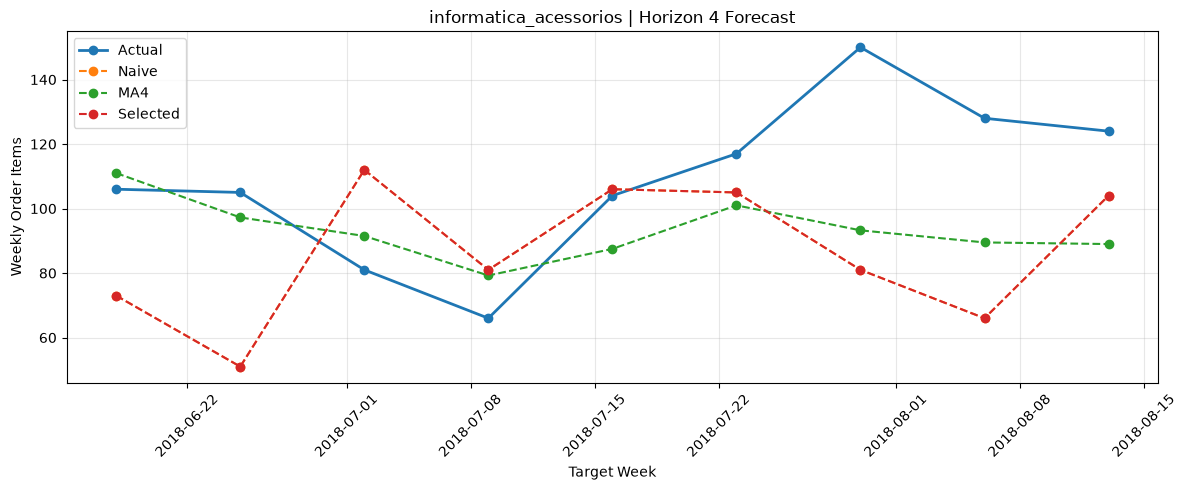

In [36]:
# TASK B-09-33. 실제값 vs 예측값 시각화

category = 'informatica_acessorios'
h = 4

# 1. 상품군 및 Horizon 선택
plot_df = test_compare_df[
    (test_compare_df['category'] == category) &
    (test_compare_df['horizon'] == h)
].copy()

# 2. 실제값
actual = (
    plot_df[plot_df['model'] == 'Selected']
    .set_index('target_date')['y_true']
    .sort_index()
)

# 3. 모델별 예측값
predictions = (
    plot_df.pivot(
        index='target_date',
        columns='model',
        values='y_pred'
    )
    .sort_index()
)

# 4. 검증
assert len(actual) == 9
assert predictions.shape == (9, 3)

# 5. 시각화
plt.figure(figsize=(12, 5))

plt.plot(
    actual.index,
    actual.values,
    marker='o',
    linewidth=2,
    label='Actual'
)

for model_name in ['Naive', 'MA4', 'Selected']:
    plt.plot(
        predictions.index,
        predictions[model_name],
        marker='o',
        linestyle='--',
        label=model_name
    )

plt.title(f'{category} | Horizon {h} Forecast')
plt.xlabel('Target Week')
plt.ylabel('Weekly Order Items')
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
# TASK B-09-34. 주별 예측오차 상세 분석

error_detail = pd.DataFrame({
    'actual': actual,
    'Naive': predictions['Naive'],
    'MA4': predictions['MA4']
})

# 예측오차: 실제값 - 예측값
error_detail['Naive_error'] = (
    error_detail['actual'] - error_detail['Naive']
)

error_detail['MA4_error'] = (
    error_detail['actual'] - error_detail['MA4']
)

display(
    error_detail.sort_values(
        'Naive_error',
        ascending=False
    ).round(2)
)

,actual,Naive,MA4,Naive_error,MA4_error
target_date,,,,,
2018-07-30,150,81.0,93.25,69.0,56.75
2018-08-06,128,66.0,89.50,62.0,38.50
2018-06-25,105,51.0,97.25,54.0,7.75
2018-06-18,106,73.0,111.00,33.0,-5.00
2018-08-13,124,104.0,89.00,20.0,35.00
2018-07-23,117,105.0,101.00,12.0,16.00
2018-07-16,104,106.0,87.50,-2.0,16.50
2018-07-09,66,81.0,79.25,-15.0,-13.25
2018-07-02,81,112.0,91.50,-31.0,-10.50


category,beleza_saude,cama_mesa_banho,esporte_lazer,informatica_acessorios,moveis_decoracao
horizon,,,,,
1,17.07,17.99,19.93,27.95,34.36
2,13.91,17.83,23.30,30.69,36.82
3,15.88,23.17,24.91,27.19,32.81
4,14.99,24.94,27.17,30.38,33.13


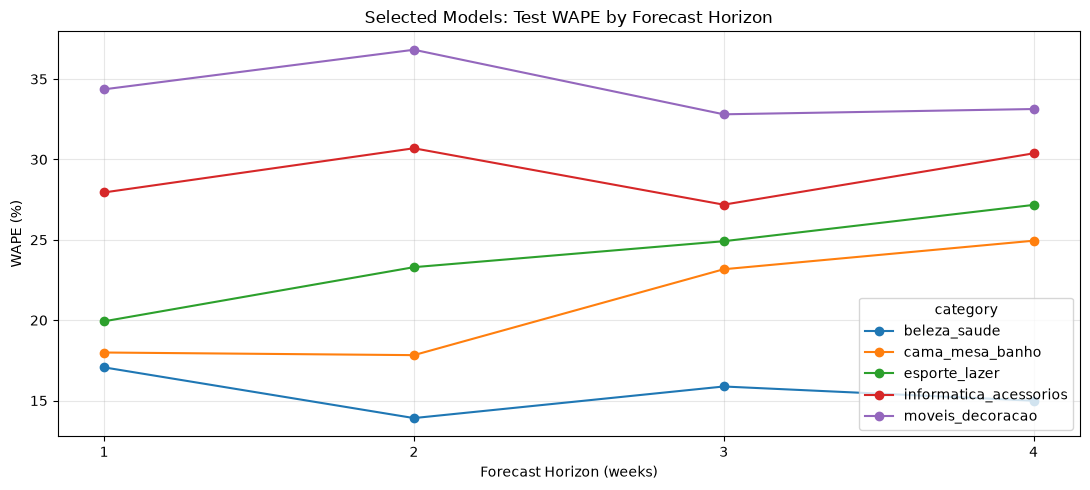

In [38]:
# TASK B-09-35. Horizon별 테스트 WAPE 시각화

selected_horizon = test_horizon_df[
    test_horizon_df['model'] == 'Selected'
].copy()

pivot = selected_horizon.pivot(
    index='horizon',
    columns='category',
    values='WAPE'
)

display(pivot.round(2))

ax = pivot.plot(
    marker='o',
    figsize=(11, 5)
)

ax.set_title('Selected Models: Test WAPE by Forecast Horizon')
ax.set_xlabel('Forecast Horizon (weeks)')
ax.set_ylabel('WAPE (%)')
ax.set_xticks([1, 2, 3, 4])
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [39]:
# TASK B-09-36. 동일한 Target Week 기준 Horizon 성능 비교

# 1. 모든 Horizon이 존재하는 날짜 추출
common_targets = (
    test_forecasts_df
    .groupby(['category', 'target_date'])['horizon']
    .nunique()
    .reset_index(name='n_horizons')
)

common_targets = common_targets[
    common_targets['n_horizons'] == 4
][['category', 'target_date']]

# 2. 공통 날짜의 예측값만 선택
aligned_df = test_forecasts_df.merge(
    common_targets,
    on=['category', 'target_date'],
    how='inner',
    validate='many_to_one'
)

# 3. 동일 기간의 Horizon별 WAPE
aligned_metrics = []

for (category, h), group in aligned_df.groupby(
    ['category', 'horizon']
):
    aligned_metrics.append({
        'category': category,
        'horizon': h,
        'n_predictions': len(group),
        'WAPE': wape(group['y_true'], group['y_pred'])
    })

aligned_metrics_df = pd.DataFrame(aligned_metrics)

aligned_pivot = aligned_metrics_df.pivot(
    index='horizon',
    columns='category',
    values='WAPE'
)

# 4. 검증
assert aligned_df.shape[0] == 120
assert aligned_metrics_df['n_predictions'].eq(6).all()

display(aligned_pivot.round(2))

category,beleza_saude,cama_mesa_banho,esporte_lazer,informatica_acessorios,moveis_decoracao
horizon,,,,,
1,13.95,18.46,21.81,20.03,28.36
2,13.74,20.94,23.16,29.02,29.04
3,14.04,25.86,19.10,24.01,27.68
4,13.37,23.01,24.40,25.39,32.78


In [40]:
# TASK B-10-01. Tableau용 테스트 예측 상세 데이터 추출

from pathlib import Path

# 1. 저장 경로
output_dir = Path(
    r"D:\portfolio\olist_portfolio\projects\B_demand_forecasting\outputs"
)
output_dir.mkdir(parents=True, exist_ok=True)

# 2. 기존 테스트 비교 결과 복사
tableau_detail = test_compare_df.copy()

# 3. Selected가 실제로 사용한 모델명 기록
tableau_detail['actual_model'] = tableau_detail.apply(
    lambda row: (
        selected_models[row['category']]
        if row['model'] == 'Selected'
        else row['model']
    ),
    axis=1
)

# 4. 오차 계산
tableau_detail['error'] = (
    tableau_detail['y_true'] - tableau_detail['y_pred']
)

tableau_detail['abs_error'] = tableau_detail['error'].abs()

# 5. 날짜 및 정렬
for col in ['origin_date', 'target_date']:
    tableau_detail[col] = pd.to_datetime(tableau_detail[col])

tableau_detail = tableau_detail.sort_values(
    ['category', 'model', 'origin_date', 'horizon']
).reset_index(drop=True)

# 6. 검증
assert tableau_detail.shape == (540, 10)
assert tableau_detail.groupby(['category', 'model']).size().eq(36).all()

# 7. CSV 저장
output_path = output_dir / 'forecast_test_detail.csv'

tableau_detail.to_csv(
    output_path,
    index=False,
    encoding='utf-8-sig'
)

print('저장 완료:', output_path)
print('데이터 크기:', tableau_detail.shape)
display(tableau_detail.head())

데이터 크기: (540, 10)


,category,model,origin_date,target_date,horizon,y_true,y_pred,actual_model,error,abs_error
0,beleza_saude,MA4,2018-05-21,2018-05-28,1,113,186.0,MA4,-73.0,73.0
1,beleza_saude,MA4,2018-05-21,2018-06-04,2,197,186.0,MA4,11.0,11.0
2,beleza_saude,MA4,2018-05-21,2018-06-11,3,223,186.0,MA4,37.0,37.0
3,beleza_saude,MA4,2018-05-21,2018-06-18,4,227,186.0,MA4,41.0,41.0
4,beleza_saude,MA4,2018-05-28,2018-06-04,1,197,156.5,MA4,40.5,40.5


In [41]:
# TASK B-10-02. Tableau용 성능 비교 및 최종 요약 CSV

# 1. 전체 13개 모델의 내부 검증 성능
model_comparison = final_metrics_df.copy()

assert model_comparison.shape == (260, 6)

model_comparison.to_csv(
    output_dir / 'forecast_model_comparison.csv',
    index=False,
    encoding='utf-8-sig'
)

# 2. 선정 모델의 내부 검증 WAPE
validation_summary = pooled_metrics_df.copy()

validation_summary['selected_model'] = (
    validation_summary['category'].map(selected_models)
)

validation_summary = (
    validation_summary[
        validation_summary['model']
        == validation_summary['selected_model']
    ]
    [['category', 'selected_model', 'WAPE']]
    .rename(columns={'WAPE': 'validation_WAPE'})
)

# 3. 테스트 구간의 기준 모델 비교 결과
test_summary = (
    test_comparison[
        ['Naive', 'MA4', 'Selected']
    ]
    .rename(columns={
        'Naive': 'test_naive_WAPE',
        'MA4': 'test_ma4_WAPE',
        'Selected': 'test_selected_WAPE'
    })
    .reset_index()
)

# 4. 통합
final_summary = validation_summary.merge(
    test_summary,
    on='category',
    validate='one_to_one'
)

# 5. 검증 대비 테스트 성능 변화 (%p)
final_summary['validation_test_gap_pp'] = (
    final_summary['test_selected_WAPE']
    - final_summary['validation_WAPE']
)

# 6. Naive 대비 상대 개선율 (%)
final_summary['improvement_vs_naive_pct'] = (
    (
        final_summary['test_naive_WAPE']
        - final_summary['test_selected_WAPE']
    )
    / final_summary['test_naive_WAPE']
    * 100
)

# 7. MA4 대비 상대 개선율 (%)
final_summary['improvement_vs_ma4_pct'] = (
    (
        final_summary['test_ma4_WAPE']
        - final_summary['test_selected_WAPE']
    )
    / final_summary['test_ma4_WAPE']
    * 100
)

# 8. 결과 검증
assert final_summary.shape == (5, 9)
assert final_summary['category'].nunique() == 5

# 9. CSV 저장
final_summary.to_csv(
    output_dir / 'forecast_final_summary.csv',
    index=False,
    encoding='utf-8-sig'
)

print('모델 비교표:', model_comparison.shape)
print('최종 요약표:', final_summary.shape)

display(final_summary.round(2))

모델 비교표: (260, 6)
최종 요약표: (5, 9)


,category,selected_model,validation_WAPE,test_naive_WAPE,test_ma4_WAPE,test_selected_WAPE,validation_test_gap_pp,improvement_vs_naive_pct,improvement_vs_ma4_pct
0,beleza_saude,AAN,22.56,25.69,20.94,15.43,-7.13,39.93,26.31
1,cama_mesa_banho,AdN,23.71,30.20,22.69,21.03,-2.68,30.35,7.33
2,esporte_lazer,AAN,23.06,27.99,22.87,23.98,0.92,14.32,-4.87
3,informatica_acessorios,Naive,36.49,29.09,22.34,29.09,-7.39,0.00,-30.24
4,moveis_decoracao,MA4,35.51,31.62,34.22,34.22,-1.29,-8.22,0.00
